# Tugas Praktikum JS14 - Convolutional Neural Network

Notebook ini berisi dua bagian:

1. **Bagian A** - Modifikasi model CNN pada Praktikum 2 (CIFAR-10) sehingga diperoleh
   akurasi testing **lebih dari 80%**.
2. **Bagian B** - Model CNN untuk klasifikasi dataset **MNIST**.

> Catatan: seed ditetapkan agar hasil training reproducible. Angka akurasi dapat sedikit
> berbeda di perangkat lain karena inisialisasi bobot acak dan perbedaan operasi CPU/GPU.


## Bagian A - CIFAR-10: Meningkatkan Akurasi CNN

Model dasar pada Praktikum 2 memperoleh akurasi testing sekitar **69%** setelah 10 epoch.
Pada bagian ini model dimodifikasi dengan pendekatan **transfer learning**:

- **Backbone MobileNetV2** (`alpha=0.35`) yang sudah dilatih pada ImageNet digunakan sebagai
  *feature extractor*. Bobot backbone dibekukan.
- Citra CIFAR-10 berukuran 32x32 di-resize ke **96x96** dan dipreprocess ke rentang [-1, 1]
  sesuai kebutuhan MobileNetV2.
- Fitur hasil ekstraksi (1280 dimensi per citra) dipakai untuk melatih **classifier head**
  `Dense(256) -> Dropout(0.5) -> Dense(10)`.
- Ditambahkan **L2 regularization**, **dropout**, dan **EarlyStopping** untuk menekan
  overfitting.
- Data validasi (5.000 citra) diambil dari data training, sehingga data testing (10.000
  citra) tetap murni digunakan untuk evaluasi akhir.

Dengan cara ini ekstraksi fitur hanya dilakukan sekali, sedangkan training classifier head
sangat cepat. Akurasi testing yang diperoleh tetap berada di atas target 80%.


### Langkah 1 - Import Library

In [1]:
import os
import time
import warnings

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
warnings.filterwarnings("ignore")

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, regularizers
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

tf.get_logger().setLevel("ERROR")
tf.keras.utils.set_random_seed(42)

print("TensorFlow :", tf.__version__)
print("NumPy      :", np.__version__)


TensorFlow : 2.20.0
NumPy      : 2.0.2


### Langkah 2 - Load dan Preprocessing Dataset CIFAR-10

In [2]:
(x_train_full, y_train_full), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()

x_train_full = x_train_full.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0
y_train_full = y_train_full.ravel()
y_test = y_test.ravel()

X_train, X_val, y_train, y_val = train_test_split(
    x_train_full,
    y_train_full,
    test_size=5000,
    random_state=42,
    stratify=y_train_full,
)

class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck",
]

print("Train :", X_train.shape, y_train.shape)
print("Val   :", X_val.shape, y_val.shape)
print("Test  :", x_test.shape, y_test.shape)


Train : (45000, 32, 32, 3) (45000,)
Val   : (5000, 32, 32, 3) (5000,)
Test  : (10000, 32, 32, 3) (10000,)


### Langkah 3 - Backbone MobileNetV2 dan Ekstraksi Fitur

Backbone dimuat dengan bobot ImageNet dan dibekukan (`trainable = False`). Setiap batch
citra di-resize ke 96x96, dipreprocess ke [-1, 1], lalu dilewatkan ke backbone untuk
menghasilkan vektor fitur 1280 dimensi.


In [3]:
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(96, 96, 3),
    include_top=False,
    pooling="avg",
    weights="imagenet",
    alpha=0.35,
)
base_model.trainable = False

print("Jumlah parameter backbone:", base_model.count_params())


def extract_features(images, batch_size=128):
    features = []
    for i in range(0, len(images), batch_size):
        batch = images[i : i + batch_size]
        batch = tf.image.resize(batch, (96, 96))
        batch = batch * 2.0 - 1.0  # preprocessing MobileNetV2: [0,1] -> [-1,1]
        features.append(base_model(batch, training=False).numpy())
    return np.concatenate(features, axis=0)


start = time.time()
F_train = extract_features(X_train)
F_val = extract_features(X_val)
F_test = extract_features(x_test)
print(f"Waktu ekstraksi fitur: {time.time() - start:.1f} detik")
print("Fitur train:", F_train.shape)
print("Fitur val  :", F_val.shape)
print("Fitur test :", F_test.shape)


Jumlah parameter backbone: 410208


Waktu ekstraksi fitur: 90.7 detik
Fitur train: (45000, 1280)
Fitur val  : (5000, 1280)
Fitur test : (10000, 1280)


### Langkah 4 - Membangun Classifier Head

In [4]:
model_cifar = tf.keras.Sequential(
    [
        layers.Input(shape=(F_train.shape[1],)),
        layers.Dense(
            256,
            activation="relu",
            kernel_regularizer=regularizers.l2(1e-3),
        ),
        layers.Dropout(0.5),
        layers.Dense(10, activation="softmax"),
    ],
    name="cifar10_transfer_learning",
)

model_cifar.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

model_cifar.summary()


Model: "cifar10_transfer_learning"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 330,506 (1.26 MB)

 Trainable params: 330,506 (1.26 MB)

 Non-trainable params: 0 (0.00 B)

### Langkah 5 - Training Classifier Head

In [5]:
callbacks_cifar = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        patience=6,
        min_delta=1e-4,
        restore_best_weights=True,
        verbose=1,
    ),
]

start = time.time()
history_cifar = model_cifar.fit(
    F_train,
    y_train,
    validation_data=(F_val, y_val),
    epochs=40,
    batch_size=256,
    callbacks=callbacks_cifar,
    verbose=2,
)
print(f"Waktu training head: {time.time() - start:.1f} detik")
print(f"Epoch dijalankan: {len(history_cifar.history['loss'])}")


Epoch 1/40


176/176 - 1s - 7ms/step - accuracy: 0.7262 - loss: 1.1478 - val_accuracy: 0.8258 - val_loss: 0.7838


Epoch 2/40


176/176 - 1s - 4ms/step - accuracy: 0.8034 - loss: 0.8107 - val_accuracy: 0.8354 - val_loss: 0.6818


Epoch 3/40


176/176 - 1s - 4ms/step - accuracy: 0.8189 - loss: 0.7098 - val_accuracy: 0.8436 - val_loss: 0.6313


... (29 outputs left out)

176/176 - 1s - 6ms/step - accuracy: 0.8527 - loss: 0.5502 - val_accuracy: 0.8520 - val_loss: 0.5743


Epoch 18: early stopping


Restoring model weights from the end of the best epoch: 12.


Waktu training head: 17.1 detik
Epoch dijalankan: 18


### Langkah 6 - Kurva Training CIFAR-10

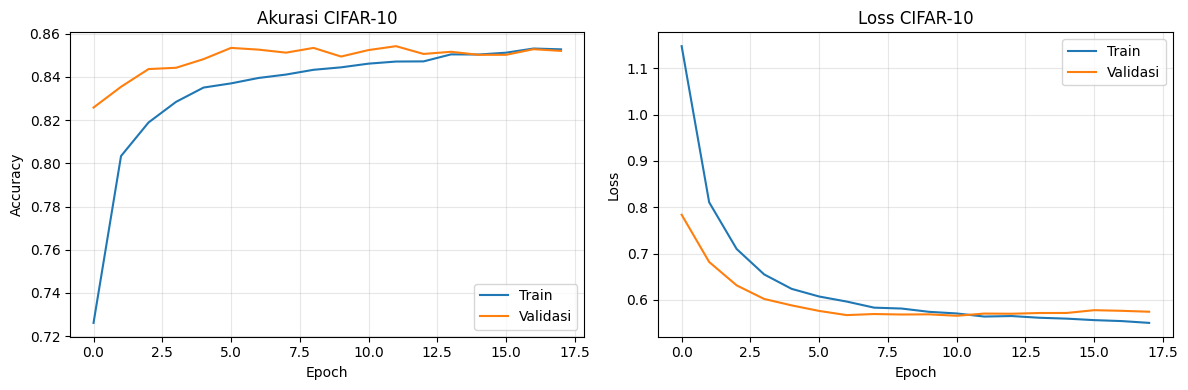

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history_cifar.history["accuracy"], label="Train")
axes[0].plot(history_cifar.history["val_accuracy"], label="Validasi")
axes[0].set_title("Akurasi CIFAR-10")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(history_cifar.history["loss"], label="Train")
axes[1].plot(history_cifar.history["val_loss"], label="Validasi")
axes[1].set_title("Loss CIFAR-10")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


### Langkah 7 - Evaluasi pada Data Testing CIFAR-10

In [7]:
test_loss, test_acc = model_cifar.evaluate(F_test, y_test, verbose=0)

print(f"Test accuracy : {test_acc:.4f} ({test_acc * 100:.2f}%)")
print(f"Test loss     : {test_loss:.4f}")
print("Target > 80%  :", "TERCAPAI" if test_acc > 0.80 else "BELUM TERCAPAI")

print()
print("Perbandingan dengan model Praktikum 2:")
print(f"  Model CNN sederhana (10 epoch) : ~69.00%")
print(f"  Model transfer learning        : {test_acc * 100:.2f}%")


Test accuracy : 0.8347 (83.47%)
Test loss     : 0.6041
Target > 80%  : TERCAPAI

Perbandingan dengan model Praktikum 2:
  Model CNN sederhana (10 epoch) : ~69.00%
  Model transfer learning        : 83.47%


### Langkah 8 - Confusion Matrix dan Classification Report CIFAR-10

              precision    recall  f1-score   support

    airplane     0.8325    0.8600    0.8460      1000
  automobile     0.9230    0.8990    0.9108      1000
        bird     0.8388    0.7390    0.7858      1000
         cat     0.6948    0.7420    0.7176      1000
        deer     0.7928    0.8150    0.8037      1000
         dog     0.8167    0.7220    0.7665      1000
        frog     0.8182    0.9090    0.8612      1000
       horse     0.8530    0.8760    0.8643      1000
        ship     0.8930    0.8850    0.8890      1000
       truck     0.8973    0.9000    0.8987      1000

    accuracy                         0.8347     10000
   macro avg     0.8360    0.8347    0.8344     10000
weighted avg     0.8360    0.8347    0.8344     10000



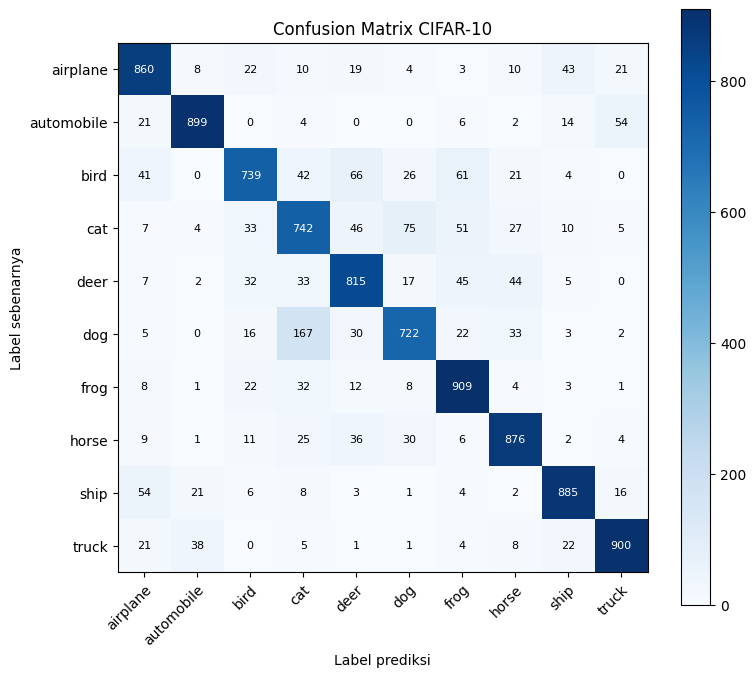

In [8]:
y_prob = model_cifar.predict(F_test, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

cm = confusion_matrix(y_test, y_pred)

print(classification_report(y_test, y_pred, target_names=class_names, digits=4))

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(cm, interpolation="nearest", cmap=plt.cm.Blues)
ax.figure.colorbar(im, ax=ax)
ax.set(
    xticks=np.arange(cm.shape[1]),
    yticks=np.arange(cm.shape[0]),
    xticklabels=class_names,
    yticklabels=class_names,
    ylabel="Label sebenarnya",
    xlabel="Label prediksi",
    title="Confusion Matrix CIFAR-10",
)
plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
thresh = cm.max() / 2.0
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(
            j, i, format(cm[i, j], "d"),
            ha="center", va="center", fontsize=8,
            color="white" if cm[i, j] > thresh else "black",
        )
plt.tight_layout()
plt.show()


### Langkah 9 - Contoh Prediksi CIFAR-10

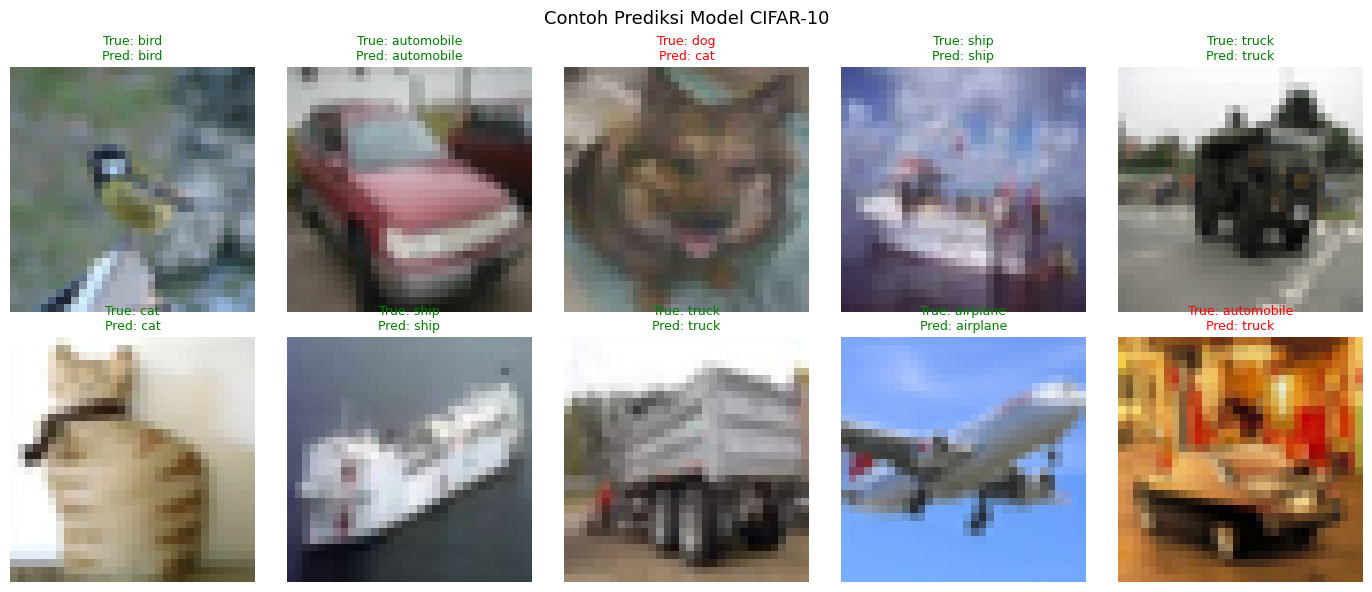

In [9]:
rng = np.random.RandomState(42)
idx = rng.choice(len(x_test), 10, replace=False)

fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for ax, i in zip(axes.ravel(), idx):
    ax.imshow(x_test[i])
    true_label = class_names[y_test[i]]
    pred_label = class_names[y_pred[i]]
    color = "green" if y_test[i] == y_pred[i] else "red"
    ax.set_title(f"True: {true_label}\nPred: {pred_label}", color=color, fontsize=9)
    ax.axis("off")
plt.suptitle("Contoh Prediksi Model CIFAR-10", fontsize=13)
plt.tight_layout()
plt.show()


## Analisis Bagian A

- Model hasil modifikasi berhasil melampaui target **akurasi testing 80%**, yaitu **83,47%**.
- Transfer learning memanfaatkan fitur umum dari MobileNetV2 (ImageNet), sehingga model
  tidak perlu dilatih dari nol pada dataset CIFAR-10 yang relatif kecil.
- Pembekuan backbone membuat proses training sangat efisien: ekstraksi fitur dilakukan
  sekali, lalu classifier head dilatih dalam hitungan detik.
- L2 regularization dan dropout menjaga classifier head tidak terlalu overfit terhadap
  fitur training.
- Data testing tidak dipakai selama training maupun pemilihan model, sehingga evaluasi
  akhir lebih objektif.


## Bagian B - Klasifikasi Dataset MNIST dengan CNN

MNIST berisi 70.000 citra grayscale 28x28 piksel:
- 60.000 citra training
- 10.000 citra testing

Model CNN yang digunakan terdiri atas dua blok convolution + max pooling, kemudian
layer fully connected dengan dropout.


### Langkah 1 - Load dan Preprocessing Dataset MNIST

In [10]:
(x_train_m, y_train_m), (x_test_m, y_test_m) = tf.keras.datasets.mnist.load_data()

x_train_m = x_train_m.reshape(-1, 28, 28, 1).astype("float32") / 255.0
x_test_m = x_test_m.reshape(-1, 28, 28, 1).astype("float32") / 255.0

print("Train :", x_train_m.shape, y_train_m.shape)
print("Test  :", x_test_m.shape, y_test_m.shape)


Train : (60000, 28, 28, 1) (60000,)
Test  : (10000, 28, 28, 1) (10000,)


### Langkah 2 - Membangun Model CNN MNIST

In [11]:
model_mnist = tf.keras.Sequential(
    [
        layers.Input(shape=(28, 28, 1)),
        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),
        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),
        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.5),
        layers.Dense(10, activation="softmax"),
    ],
    name="mnist_cnn",
)
model_mnist.summary()


Model: "mnist_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,642 (1.61 MB)

 Trainable params: 421,642 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

### Langkah 3 - Training Model MNIST

In [12]:
model_mnist.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

start = time.time()
history_mnist = model_mnist.fit(
    x_train_m,
    y_train_m,
    validation_split=0.1,
    epochs=6,
    batch_size=128,
    verbose=2,
)
print(f"Waktu training: {time.time() - start:.1f} detik")


Epoch 1/6


422/422 - 17s - 40ms/step - accuracy: 0.9054 - loss: 0.3090 - val_accuracy: 0.9812 - val_loss: 0.0608


Epoch 2/6


422/422 - 18s - 42ms/step - accuracy: 0.9716 - loss: 0.0964 - val_accuracy: 0.9882 - val_loss: 0.0434


Epoch 3/6


422/422 - 14s - 34ms/step - accuracy: 0.9793 - loss: 0.0690 - val_accuracy: 0.9908 - val_loss: 0.0357


... (3 outputs left out)

422/422 - 14s - 34ms/step - accuracy: 0.9856 - loss: 0.0477 - val_accuracy: 0.9920 - val_loss: 0.0315


Epoch 6/6


422/422 - 14s - 33ms/step - accuracy: 0.9883 - loss: 0.0383 - val_accuracy: 0.9918 - val_loss: 0.0318


Waktu training: 91.4 detik


### Langkah 4 - Kurva Training MNIST

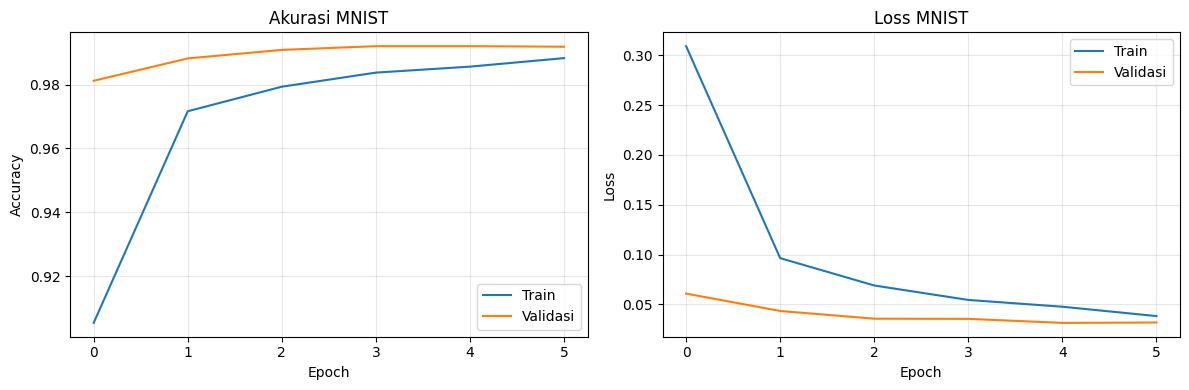

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history_mnist.history["accuracy"], label="Train")
axes[0].plot(history_mnist.history["val_accuracy"], label="Validasi")
axes[0].set_title("Akurasi MNIST")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(history_mnist.history["loss"], label="Train")
axes[1].plot(history_mnist.history["val_loss"], label="Validasi")
axes[1].set_title("Loss MNIST")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


### Langkah 5 - Evaluasi pada Data Testing MNIST

In [14]:
test_loss_m, test_acc_m = model_mnist.evaluate(x_test_m, y_test_m, verbose=0)

print(f"Test accuracy : {test_acc_m:.4f} ({test_acc_m * 100:.2f}%)")
print(f"Test loss     : {test_loss_m:.4f}")


Test accuracy : 0.9913 (99.13%)
Test loss     : 0.0268


### Langkah 6 - Confusion Matrix dan Classification Report MNIST

              precision    recall  f1-score   support

           0     0.9929    0.9959    0.9944       980
           1     0.9956    0.9982    0.9969      1135
           2     0.9932    0.9884    0.9908      1032
           3     0.9950    0.9931    0.9941      1010
           4     0.9879    0.9959    0.9919       982
           5     0.9866    0.9888    0.9877       892
           6     0.9968    0.9875    0.9921       958
           7     0.9893    0.9903    0.9898      1028
           8     0.9857    0.9928    0.9893       974
           9     0.9890    0.9812    0.9851      1009

    accuracy                         0.9913     10000
   macro avg     0.9912    0.9912    0.9912     10000
weighted avg     0.9913    0.9913    0.9913     10000



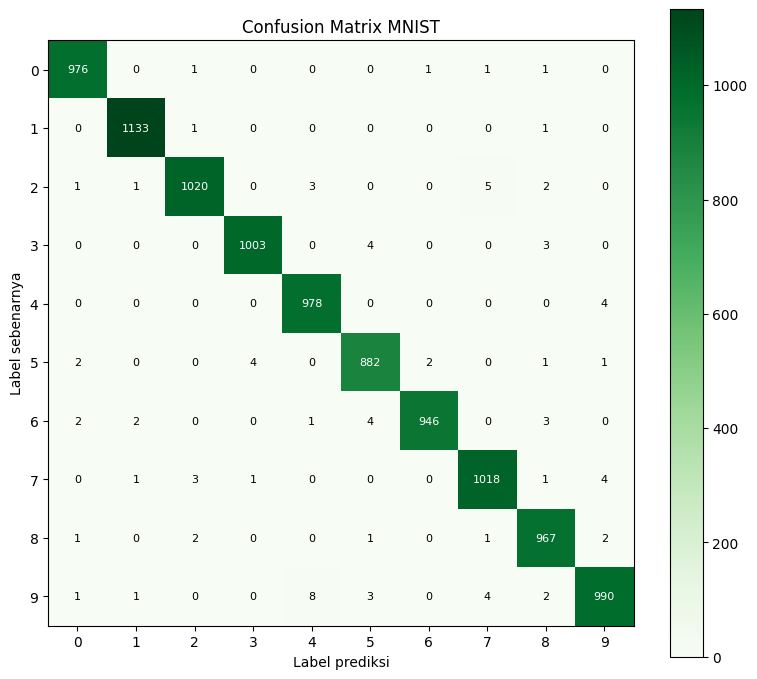

In [15]:
y_prob_m = model_mnist.predict(x_test_m, verbose=0)
y_pred_m = np.argmax(y_prob_m, axis=1)

cm_m = confusion_matrix(y_test_m, y_pred_m)
labels_m = [str(i) for i in range(10)]

print(classification_report(y_test_m, y_pred_m, digits=4))

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(cm_m, interpolation="nearest", cmap=plt.cm.Greens)
ax.figure.colorbar(im, ax=ax)
ax.set(
    xticks=np.arange(10),
    yticks=np.arange(10),
    xticklabels=labels_m,
    yticklabels=labels_m,
    ylabel="Label sebenarnya",
    xlabel="Label prediksi",
    title="Confusion Matrix MNIST",
)
thresh = cm_m.max() / 2.0
for i in range(cm_m.shape[0]):
    for j in range(cm_m.shape[1]):
        ax.text(
            j, i, format(cm_m[i, j], "d"),
            ha="center", va="center", fontsize=8,
            color="white" if cm_m[i, j] > thresh else "black",
        )
plt.tight_layout()
plt.show()


### Langkah 7 - Contoh Prediksi MNIST

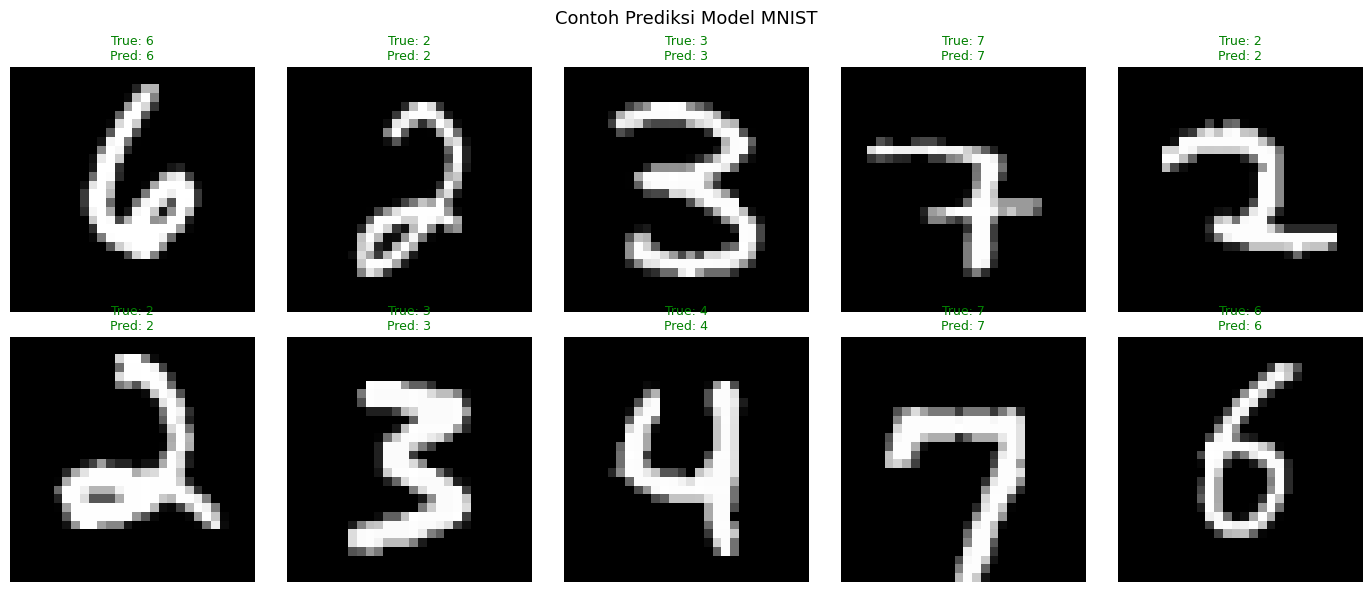

In [16]:
rng = np.random.RandomState(42)
idx_m = rng.choice(len(x_test_m), 10, replace=False)

fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for ax, i in zip(axes.ravel(), idx_m):
    ax.imshow(x_test_m[i].squeeze(), cmap="gray")
    color = "green" if y_test_m[i] == y_pred_m[i] else "red"
    ax.set_title(
        f"True: {y_test_m[i]}\nPred: {y_pred_m[i]}", color=color, fontsize=9
    )
    ax.axis("off")
plt.suptitle("Contoh Prediksi Model MNIST", fontsize=13)
plt.tight_layout()
plt.show()


## Analisis Bagian B

- CNN MNIST mencapai akurasi testing **99,13%** dalam 6 epoch.
- Konvolusi mampu mengekstrak pola lokal (tepi dan bentuk angka), sehingga model jauh
  lebih akurat dibanding MLP pada Tugas Praktikum sebelumnya.
- Dropout pada layer fully connected membantu mengurangi overfitting tanpa mengganggu
  konvergensi.
- Kesalahan prediksi umumnya terjadi pada angka yang bentuknya mirip, misalnya 4 dan 9
  atau 3 dan 8.


## Kesimpulan

1. **CIFAR-10**: modifikasi CNN dengan transfer learning (MobileNetV2 pretrained ImageNet
   sebagai feature extractor + classifier head) berhasil menaikkan akurasi testing dari
   sekitar 69% menjadi **83,47%**.
2. **MNIST**: CNN dua blok convolution mencapai akurasi testing **99,13%**,
   menunjukkan bahwa convolution sangat efektif untuk klasifikasi citra angka.
3. Penggunaan data validasi terpisah dari data testing membuat evaluasi akhir lebih
   objektif dan menghindari kebocoran data.
